1.1 Top 20 countries by total deaths
Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761641.0
ITALY            417297.0
SYRIA            358326.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0


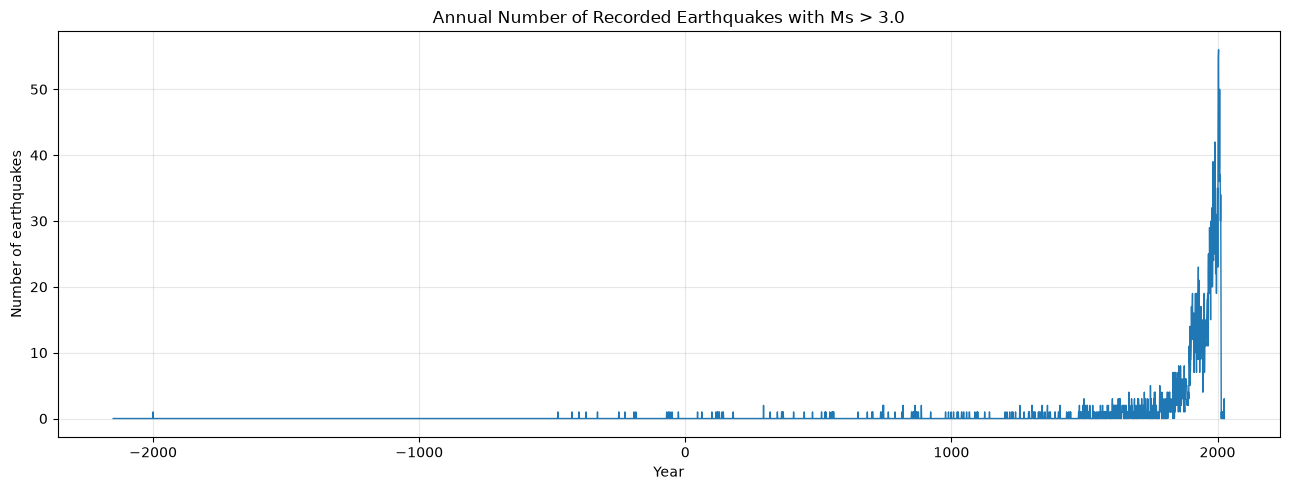

1.2 Trend:
The number of recorded earthquakes changes over time. However, this database contains significant earthquakes rather than all earthquakes, and many records have no Ms value. Therefore, the observed pattern cannot directly represent changes in the actual global earthquake frequency.
1.3 Earthquake count and largest earthquake by country
                                     Country  Total_Earthquakes Largest_Eq_Date                                  Largest_Eq_Location  Largest_Eq_Mag
                                       CHINA                626      1668-07-25                            CHINA:  SHANDONG PROVINCE             8.5
                                       JAPAN                429      2011-03-11                                       JAPAN:  HONSHU             9.1
                                   INDONESIA                427      2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST             9.1
                                        IRAN           

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Sig_Eqs = pd.read_csv(
    'earthquakes-2026-10-20_21-48-39_+0800.tsv',
    sep='\t',
    low_memory=False
)

# 1.1
top20_deaths = (
    Sig_Eqs.dropna(subset=['Country', 'Total Deaths'])
    .groupby('Country')['Total Deaths']
    .sum()
    .sort_values(ascending=False)
    .head(20)
)
print('1.1 Top 20 countries by total deaths')
print(top20_deaths.to_string())


# 1.2
ms_eqs = Sig_Eqs.dropna(subset=['Year', 'Ms'])
ms_eqs = ms_eqs[ms_eqs['Ms'] > 3.0]

annual_counts = ms_eqs.groupby('Year').size()
all_years = range(
    int(Sig_Eqs['Year'].min()),
    int(Sig_Eqs['Year'].max()) + 1
)
annual_counts = annual_counts.reindex(all_years, fill_value=0)

plt.figure(figsize=(13, 5))
plt.plot(annual_counts.index, annual_counts.values, linewidth=1)
plt.title('Annual Number of Recorded Earthquakes with Ms > 3.0')
plt.xlabel('Year')
plt.ylabel('Number of earthquakes')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('1.2 Trend:')
print(
    'The number of recorded earthquakes changes over time. '
    'However, this database contains significant earthquakes rather than '
    'all earthquakes, and many records have no Ms value. Therefore, the '
    'observed pattern cannot directly represent changes in the actual '
    'global earthquake frequency.'
)


# 1.3
def format_eq_date(row):
    if pd.isna(row['Year']):
        return None

    year = int(row['Year'])
    year_text = f'{abs(year)} B.C.' if year < 0 else str(year)

    if pd.isna(row['Mo']):
        return year_text

    month = int(row['Mo'])
    if pd.isna(row['Dy']):
        return f'{year_text}-{month:02d}'

    day = int(row['Dy'])
    return f'{year_text}-{month:02d}-{day:02d}'


def CountEq_LargestEq(country_name):
    country_df = Sig_Eqs[Sig_Eqs['Country'] == country_name]
    total_count = len(country_df)

    if total_count == 0:
        return 0, None, None, None

    valid_mag = country_df.dropna(subset=['Mag'])
    if valid_mag.empty:
        return total_count, None, None, None

    largest_eq = valid_mag.loc[valid_mag['Mag'].idxmax()]
    date = format_eq_date(largest_eq)
    location = (
        largest_eq['Location Name']
        if pd.notna(largest_eq['Location Name'])
        else None
    )

    return total_count, date, location, largest_eq['Mag']


results = []
for country in Sig_Eqs['Country'].dropna().unique():
    count, date, location, magnitude = CountEq_LargestEq(country)
    results.append((country, count, date, location, magnitude))

part_1_3 = pd.DataFrame(
    results,
    columns=[
        'Country',
        'Total_Earthquakes',
        'Largest_Eq_Date',
        'Largest_Eq_Location',
        'Largest_Eq_Mag'
    ]
).sort_values(
    'Total_Earthquakes',
    ascending=False
).reset_index(drop=True)

print('1.3 Earthquake count and largest earthquake by country')
print(part_1_3.to_string(index=False))

Total records: 235674
Missing or invalid temperature records: 797
Last observation: 2022-10-10 23:00:00


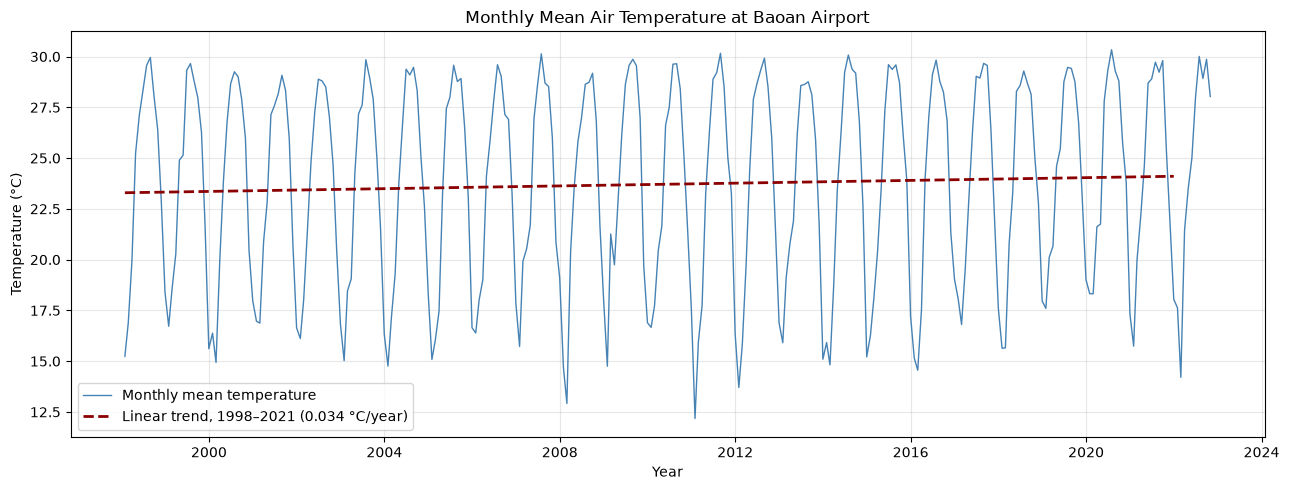

Linear trend for complete years 1998–2021: 0.0339 °C/year
The monthly mean temperature shows strong seasonal variation and a gradual upward linear trend. Data for 2022 end on October 10, so 2022 is shown in the time series but excluded from the trend fit.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2
df = pd.read_csv(
    'Baoan_Weather_1998_2022.csv',
    usecols=['DATE', 'TMP'],
    parse_dates=['DATE']
)

tmp_parts = df['TMP'].str.split(',', expand=True)
temperature = pd.to_numeric(tmp_parts[0], errors='coerce')
quality_code = tmp_parts[1]

df['TEMP_C'] = temperature.where(
    (temperature != 9999) & (quality_code != '9')
) / 10

print('Total records:', len(df))
print('Missing or invalid temperature records:', df['TEMP_C'].isna().sum())
print('Last observation:', df['DATE'].max())

monthly_temp = (
    df.set_index('DATE')['TEMP_C']
    .sort_index()
    .resample('ME')
    .mean()
)

complete_months = monthly_temp.loc['1998-01':'2021-12'].dropna()
x = complete_months.index.year + (complete_months.index.month - 1) / 12
slope, intercept = np.polyfit(x, complete_months.values, 1)

trend = intercept + slope * x

plt.figure(figsize=(13, 5))
plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    color='steelblue',
    linewidth=1,
    label='Monthly mean temperature'
)
plt.plot(
    complete_months.index,
    trend,
    color='darkred',
    linestyle='--',
    linewidth=2,
    label=f'Linear trend, 1998–2021 ({slope:.3f} °C/year)'
)

plt.title('Monthly Mean Air Temperature at Baoan Airport')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Linear trend for complete years 1998–2021: {slope:.4f} °C/year')
print(
    'The monthly mean temperature shows strong seasonal variation '
    'and a gradual upward linear trend. Data for 2022 end on '
    'October 10, so 2022 is shown in the time series but excluded '
    'from the trend fit.'
)

3.1 Top 10 storms by maximum WMO_WIND
                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291       NaN     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0

3.2 Wind speeds of the 20 strongest storms
SID
2015293N13266    185.0
1980214N11330    165.0
1935241N23291    160.0
1988253N12306    160.0
1997253N12255    160.0
2005289N18282    160.0
2019236N10314    160.0
1998295N12284    155.0
2005261N21290    155.0
2009288N07267    155.0
2017242N16333    155.0
1932304N15305    150.0
1955265N13307    150.0
1959249N19181    150.0
1969226N18280    150.0
1977242N27272    150.0
1979238N12324    150.0
1992230N11325    150.0
1994222N11267    150.0
2005236N23285    150.0

3.3 Number of datapoints by basin
BASIN
WP   

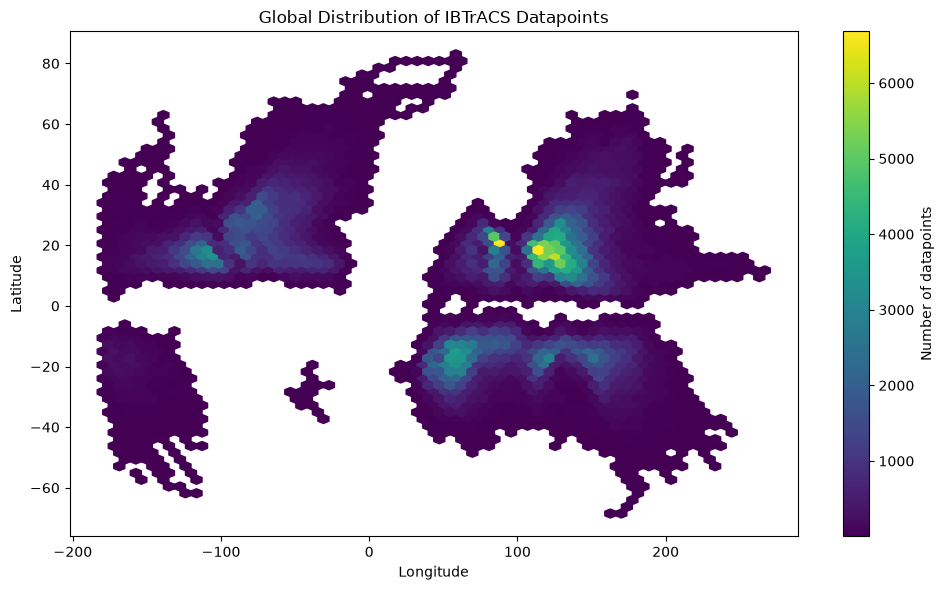


3.5 Mangkhut SID: <ArrowStringArray>
['2018250N12170']
Length: 1, dtype: str


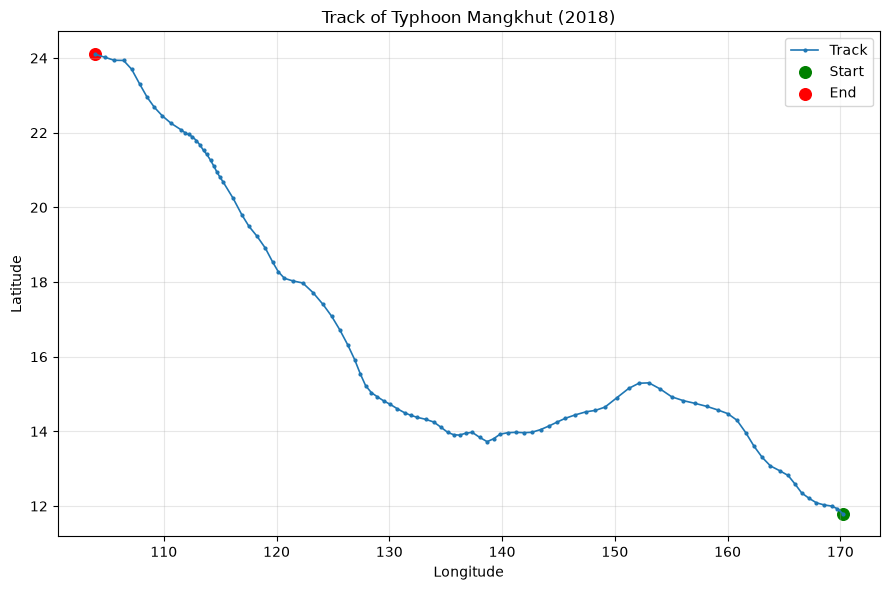


3.6 Filtered dataframe shape: (176352, 17)


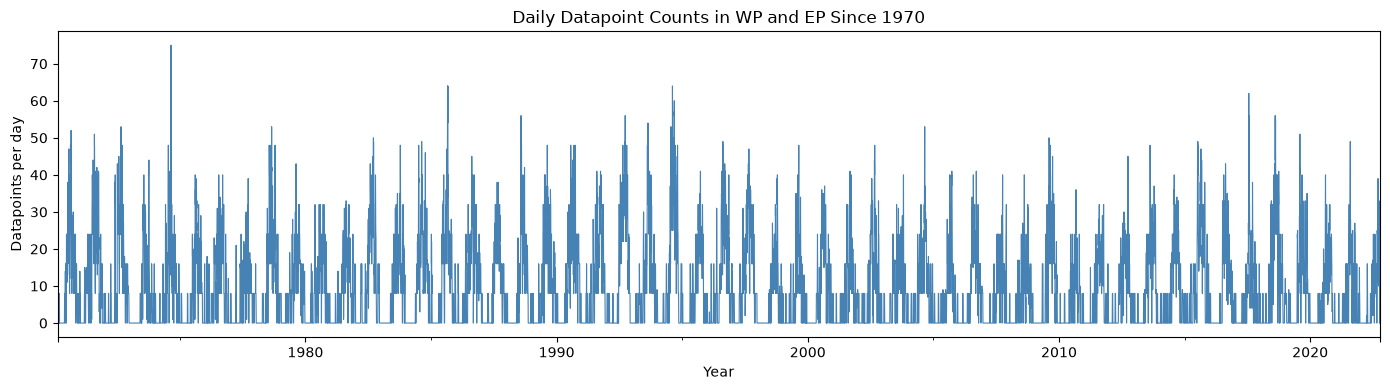

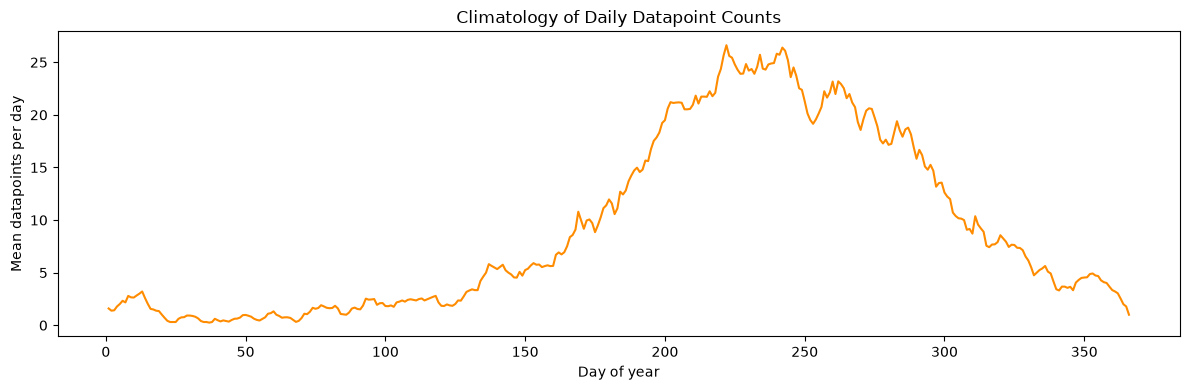

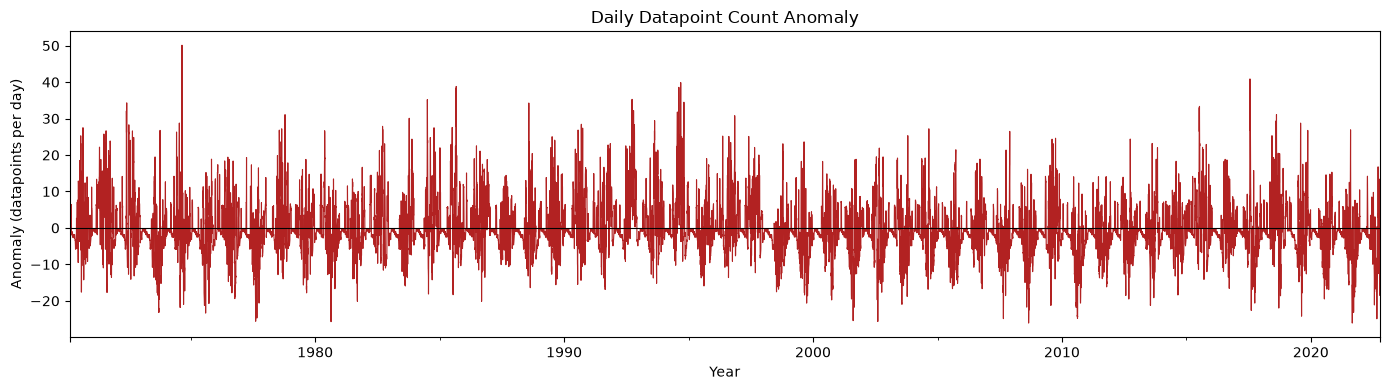

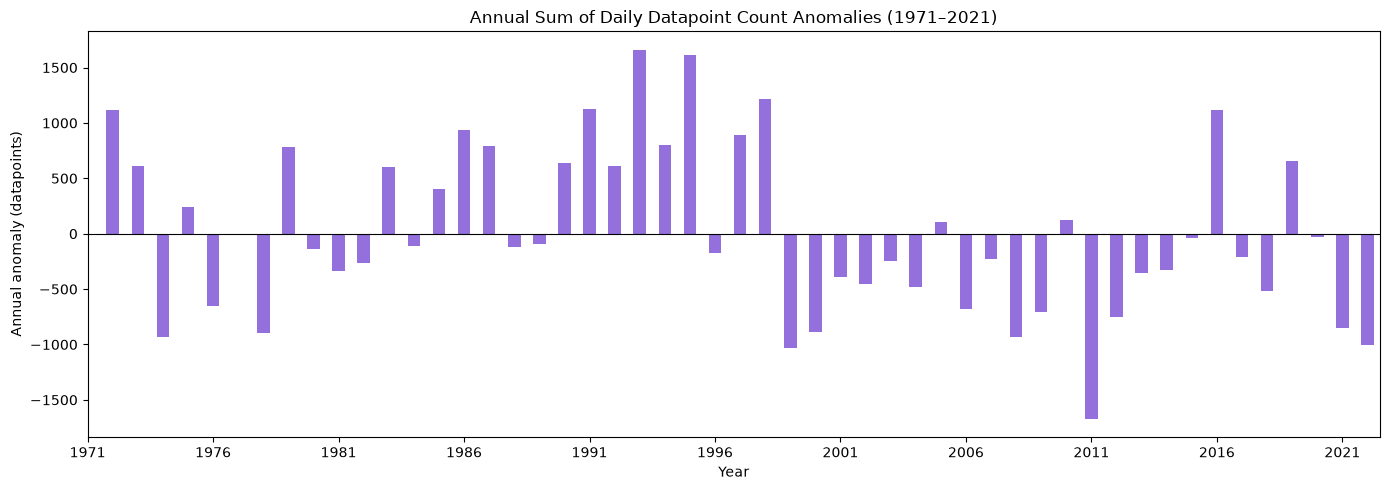


3.10 Highest annual anomalies
ISO_TIME
1992-12-31    1660.725327
1994-12-31    1611.725327
1997-12-31    1215.725327
1990-12-31    1121.725327
2015-12-31    1119.725327

3.10 Lowest annual anomalies
ISO_TIME
2010-12-31   -1668.274673
1998-12-31   -1033.274673
2021-12-31   -1004.274673
2007-12-31    -935.274673
1973-12-31    -933.274673


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    'ibtracs.ALL.list.v04r00.csv',
    usecols=range(17),
    skiprows=[1, 2],
    keep_default_na=False,
    low_memory=False
)

df['NAME'] = df['NAME'].str.strip().replace(
    ['', 'NOT_NAMED', 'NAME'], pd.NA
)
df['BASIN'] = df['BASIN'].str.strip().replace('', pd.NA)
df['ISO_TIME'] = pd.to_datetime(df['ISO_TIME'], errors='coerce')
df['WMO_WIND'] = pd.to_numeric(df['WMO_WIND'], errors='coerce')
df['LAT'] = pd.to_numeric(df['LAT'], errors='coerce')
df['LON'] = pd.to_numeric(df['LON'], errors='coerce')


# 3.1
storm_wind = df.groupby('SID')['WMO_WIND'].max().dropna()
top10_wind = storm_wind.nlargest(10)
storm_names = df.groupby('SID')['NAME'].first()

top10_storms = pd.DataFrame({
    'NAME': storm_names.reindex(top10_wind.index),
    'WMO_WIND': top10_wind
})

print('3.1 Top 10 storms by maximum WMO_WIND')
print(top10_storms.to_string())


# 3.2
top20_wind = storm_wind.nlargest(20)

print('\n3.2 Wind speeds of the 20 strongest storms')
print(top20_wind.to_string())


# 3.3
basin_counts = df['BASIN'].value_counts(dropna=False)

print('\n3.3 Number of datapoints by basin')
print(basin_counts.to_string())


# 3.4
locations = df.dropna(subset=['LAT', 'LON'])

plt.figure(figsize=(10, 6))
plt.hexbin(
    locations['LON'],
    locations['LAT'],
    gridsize=60,
    cmap='viridis',
    mincnt=1
)
plt.colorbar(label='Number of datapoints')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Global Distribution of IBTrACS Datapoints')
plt.tight_layout()
plt.show()


# 3.5
mangkhut = df[
    (df['NAME'] == 'MANGKHUT') &
    (df['SEASON'] == 2018)
].dropna(subset=['ISO_TIME', 'LAT', 'LON'])

mangkhut = mangkhut.sort_values('ISO_TIME')

print('\n3.5 Mangkhut SID:', mangkhut['SID'].unique())

plt.figure(figsize=(9, 6))
plt.plot(
    mangkhut['LON'],
    mangkhut['LAT'],
    '-o',
    markersize=2,
    linewidth=1.2,
    label='Track'
)
plt.scatter(
    mangkhut['LON'].iloc[0],
    mangkhut['LAT'].iloc[0],
    color='green',
    s=70,
    label='Start'
)
plt.scatter(
    mangkhut['LON'].iloc[-1],
    mangkhut['LAT'].iloc[-1],
    color='red',
    s=70,
    label='End'
)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Track of Typhoon Mangkhut (2018)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# 3.6
df2 = df[
    (df['ISO_TIME'] >= '1970-01-01') &
    (df['BASIN'].isin(['WP', 'EP']))
].dropna(subset=['ISO_TIME']).copy()

print('\n3.6 Filtered dataframe shape:', df2.shape)


# 3.7
daily_counts = (
    df2.set_index('ISO_TIME')
    .sort_index()
    .resample('D')
    .size()
)

plt.figure(figsize=(14, 4))
daily_counts.plot(color='steelblue', linewidth=0.8)
plt.title('Daily Datapoint Counts in WP and EP Since 1970')
plt.xlabel('Year')
plt.ylabel('Datapoints per day')
plt.tight_layout()
plt.show()


# 3.8
climatology = daily_counts.groupby(
    daily_counts.index.dayofyear
).mean()

plt.figure(figsize=(12, 4))
climatology.plot(color='darkorange')
plt.title('Climatology of Daily Datapoint Counts')
plt.xlabel('Day of year')
plt.ylabel('Mean datapoints per day')
plt.tight_layout()
plt.show()


# 3.9
expected_counts = daily_counts.index.dayofyear.map(climatology)
daily_anomaly = daily_counts - expected_counts.to_numpy()

plt.figure(figsize=(14, 4))
daily_anomaly.plot(color='firebrick', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Daily Datapoint Count Anomaly')
plt.xlabel('Year')
plt.ylabel('Anomaly (datapoints per day)')
plt.tight_layout()
plt.show()


# 3.10
annual_anomaly = daily_anomaly.resample('YE').sum()
complete_years = annual_anomaly.loc['1971':'2021']

plt.figure(figsize=(14, 5))
complete_years.plot(kind='bar', color='mediumpurple')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Annual Sum of Daily Datapoint Count Anomalies (1971–2021)')
plt.xlabel('Year')
plt.ylabel('Annual anomaly (datapoints)')
plt.xticks(
    range(0, len(complete_years), 5),
    complete_years.index.year[::5],
    rotation=0
)
plt.tight_layout()
plt.show()

print('\n3.10 Highest annual anomalies')
print(complete_years.nlargest(5).to_string())

print('\n3.10 Lowest annual anomalies')
print(complete_years.nsmallest(5).to_string())

4.1 Data cleaning
Station: ANCHOR MINE, NM US
Period: 1911-07 to 1920-09
Total months: 111
Valid months: 103
Missing months: 8


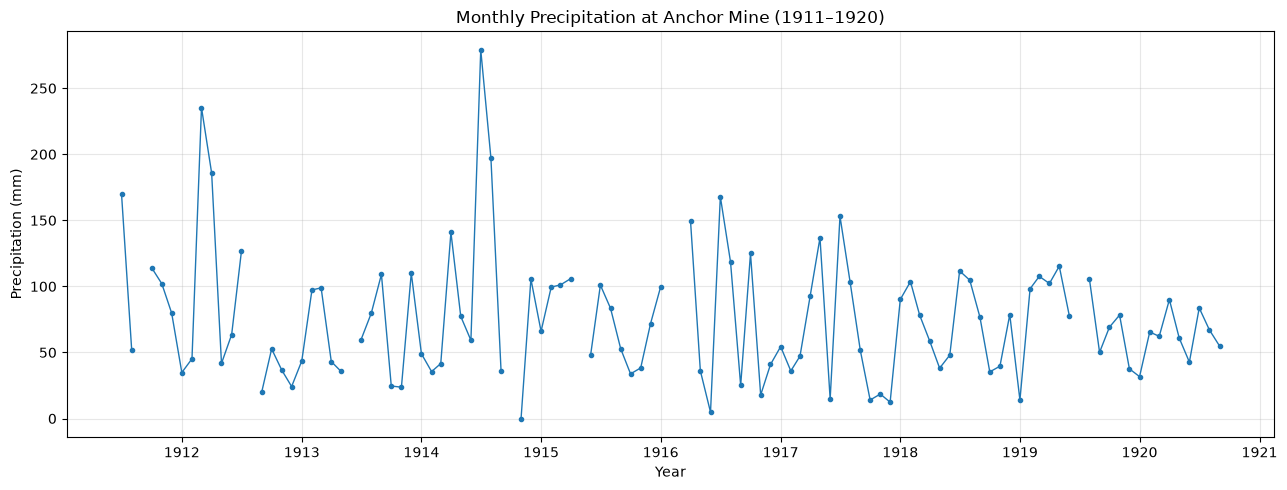


4.3 Statistical checks
1. Mean monthly precipitation: 75.05 mm
2. Median monthly precipitation: 65.50 mm
3. Standard deviation: 48.59 mm
4. Wettest month: 1914-07, 279.1 mm
5. Driest month: 1914-11, 0.0 mm
6. Linear slope: -0.199 mm per month (-2.389 mm per year)
7. Mean precipitation by calendar month:
1      53.7
2      72.6
3      96.5
4     107.6
5      67.7
6      44.8
7     139.3
8     101.3
9      52.9
10     58.6
11     39.4
12     62.3


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 4.1
df = pd.read_csv(
    'USC00290396.csv',
    usecols=['DATE', 'NAME', 'PRCP']
)

df['DATE'] = pd.to_datetime(df['DATE'], format='%Y-%m')
df['PRCP'] = pd.to_numeric(df['PRCP'], errors='coerce')
df.loc[df['PRCP'] < 0, 'PRCP'] = np.nan

df = df.set_index('DATE').sort_index()
station_name = df['NAME'].iloc[0]

all_months = pd.date_range(
    df.index.min(),
    df.index.max(),
    freq='MS'
)
prcp = df['PRCP'].reindex(all_months)
valid_prcp = prcp.dropna()

print('4.1 Data cleaning')
print('Station:', station_name)
print('Period:', prcp.index.min().strftime('%Y-%m'),
      'to', prcp.index.max().strftime('%Y-%m'))
print('Total months:', len(prcp))
print('Valid months:', len(valid_prcp))
print('Missing months:', prcp.isna().sum())


# 4.2
plt.figure(figsize=(13, 5))
plt.plot(prcp.index, prcp, marker='o', markersize=3, linewidth=1)
plt.title('Monthly Precipitation at Anchor Mine (1911–1920)')
plt.xlabel('Year')
plt.ylabel('Precipitation (mm)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 4.3
mean_prcp = valid_prcp.mean()
median_prcp = valid_prcp.median()
std_prcp = valid_prcp.std()
max_month = valid_prcp.idxmax()
min_month = valid_prcp.idxmin()
monthly_climatology = valid_prcp.groupby(
    valid_prcp.index.month
).mean()

elapsed_months = (
    (valid_prcp.index.year - valid_prcp.index.year.min()) * 12
    + valid_prcp.index.month - valid_prcp.index.month.min()
)
slope, intercept = np.polyfit(
    elapsed_months,
    valid_prcp.values,
    1
)

print('\n4.3 Statistical checks')
print(f'1. Mean monthly precipitation: {mean_prcp:.2f} mm')
print(f'2. Median monthly precipitation: {median_prcp:.2f} mm')
print(f'3. Standard deviation: {std_prcp:.2f} mm')
print(
    f'4. Wettest month: {max_month:%Y-%m}, '
    f'{valid_prcp.max():.1f} mm'
)
print(
    f'5. Driest month: {min_month:%Y-%m}, '
    f'{valid_prcp.min():.1f} mm'
)
print(
    f'6. Linear slope: {slope:.3f} mm per month '
    f'({slope * 12:.3f} mm per year)'
)
print('7. Mean precipitation by calendar month:')
print(monthly_climatology.round(1).to_string())